# Objectifs d'apprentissage – Semaine 9

À l'issue de cette semaine, l'étudiant sera capable de :

- **Distinguer** les filtres RIF (FIR) et RII (IIR) et leurs caractéristiques.
- **Concevoir** des filtres RIF par la méthode du fenêtrage.
- **Concevoir** des filtres RII par la méthode de la transformée bilinéaire (Butterworth, Chebyshev, Elliptique).
- **Analyser** la réponse fréquentielle (gain, phase) d'un filtre.
- **Visualiser** les pôles et zéros des filtres.
- **Choisir** le type de filtre (passe-bas, passe-haut, passe-bande, coupe-bande) en fonction des spécifications.
- **Utiliser** `scipy.signal` pour concevoir et appliquer des filtres numériques.
- **Évaluer** l'impact du filtrage sur un signal (réduction de bruit, extraction de composantes).

# 1. Rappels théoriques

## 1.1 Filtres RIF (FIR)

Les filtres à réponse impulsionnelle finie (RIF) ont une réponse impulsionnelle $h[n]$ de durée finie.

Équation aux différences :
$$ y[n] = \sum_{k=0}^{M} b_k \, x[n-k] $$

Propriétés :
- Toujours stables (si les coefficients sont finis).
- Peuvent avoir une phase linéaire (si les coefficients sont symétriques).
- Nécessitent un ordre généralement plus élevé que les RII pour des spécifications similaires.

**Méthodes de conception** :
- Fenêtrage (méthode simple) : troncature de la réponse impulsionnelle idéale multipliée par une fenêtre (Hamming, Hanning, etc.).
- Échantillonnage fréquentiel.
- Optimisation (Remez, moindres carrés).

## 1.2 Filtres RII (IIR)

Les filtres à réponse impulsionnelle infinie (RII) ont une réponse impulsionnelle de durée infinie.

Équation aux différences :
$$ \sum_{k=0}^{N} a_k \, y[n-k] = \sum_{k=0}^{M} b_k \, x[n-k] $$
avec $a_0 = 1$.

Propriétés :
- Peuvent être instables (pôles en dehors du cercle unité).
- Phase non linéaire en général.
- Ordre plus faible que les RIF pour les mêmes spécifications.

**Méthodes de conception** :
- Transformation bilinéaire à partir d'un filtre analogique (Butterworth, Chebyshev, Elliptique).
- Approximation par impulsion invariante.

## 1.3 Types de filtres fréquentiels

- **Passe-bas** : laisse passer les basses fréquences, atténue les hautes.
- **Passe-haut** : laisse passer les hautes fréquences, atténue les basses.
- **Passe-bande** : laisse passer une bande de fréquences.
- **Coupe-bande** : atténue une bande de fréquences (rejette).

---

# 2. Démonstrations Python

## 2.1 Conception d'un filtre RIF par fenêtrage

Nous allons concevoir un filtre passe-bas RIF en utilisant la méthode du fenêtrage.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq

print("Bibliothèques chargées.")

Bibliothèques chargées.


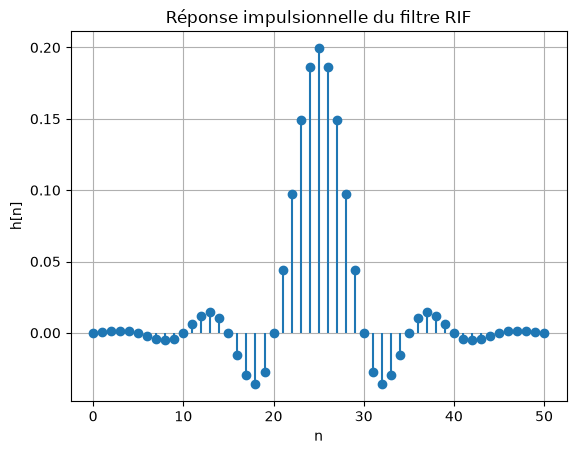

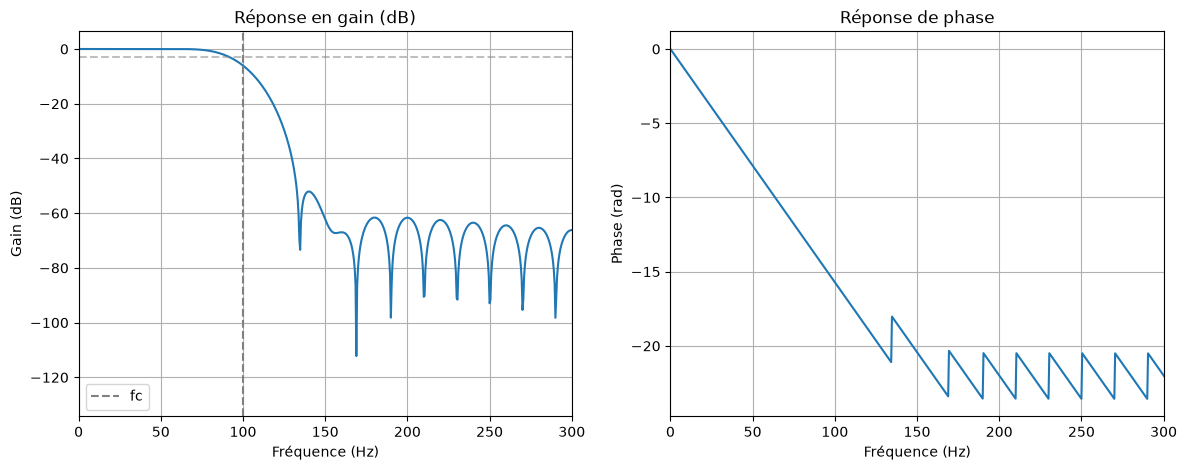

Les coefficients sont symétriques : True


In [2]:
# Paramètres du filtre
fs = 1000  # fréquence d'échantillonnage (Hz)
fc = 100   # fréquence de coupure (Hz)
N = 51     # nombre de coefficients (ordre M = N-1)

# Conception par fenêtrage de Hamming
b_fir = signal.firwin(N, fc, fs=fs, window='hamming', pass_zero='lowpass')

# Réponse impulsionnelle
n = np.arange(N)
plt.stem(n, b_fir, basefmt=' ')
plt.title('Réponse impulsionnelle du filtre RIF')
plt.xlabel('n')
plt.ylabel('h[n]')
plt.grid()
plt.show()

# Réponse fréquentielle
w, H = signal.freqz(b_fir, a=1, worN=1024)
freqs = w * fs / (2 * np.pi)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, 20*np.log10(np.abs(H)))
plt.axvline(fc, color='gray', linestyle='--', label='fc')
plt.axhline(-3, color='gray', linestyle='--', alpha=0.5)
plt.title('Réponse en gain (dB)')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Gain (dB)')
plt.xlim(0, 300)
plt.grid()
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(freqs, np.unwrap(np.angle(H)))
plt.title('Réponse de phase')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.xlim(0, 300)
plt.grid()
plt.show()

# Vérification de la phase linéaire (pour RIF symétrique)
print("Les coefficients sont symétriques :", np.allclose(b_fir, b_fir[::-1]))

## 2.2 Conception d'un filtre RII (Butterworth)

Nous allons concevoir un filtre passe-bas RII de type Butterworth.

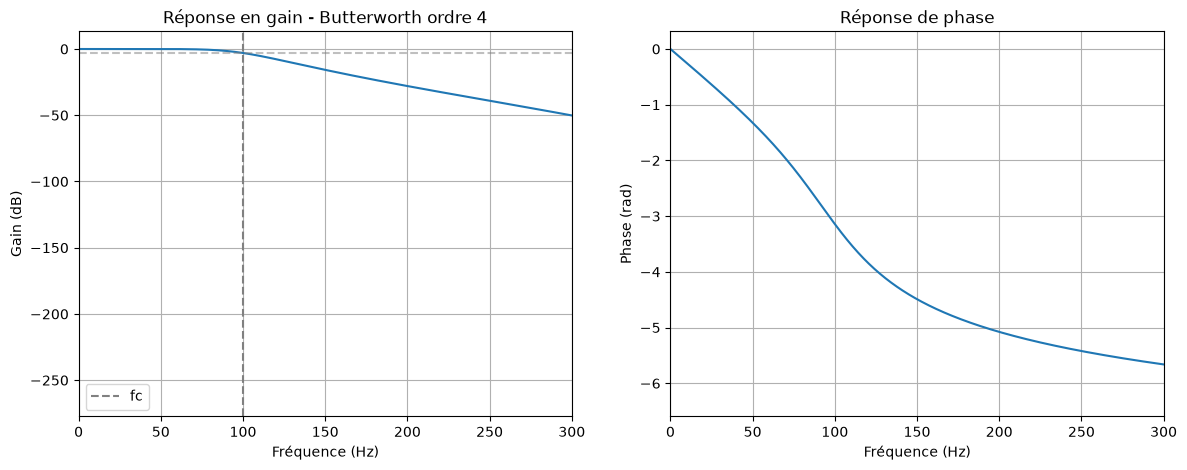

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


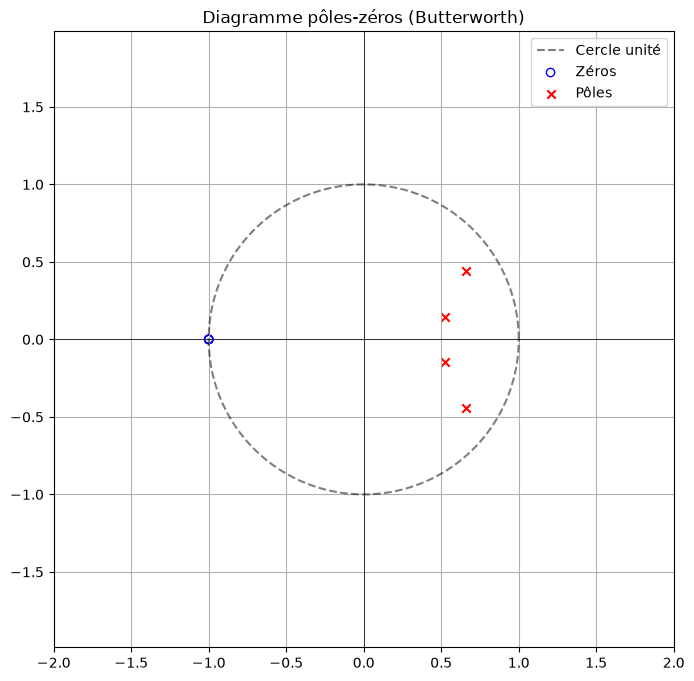

Système stable : True


In [3]:
order = 4
fc = 100
fs = 1000

# Conception
b_iir, a_iir = signal.butter(order, fc, fs=fs, btype='low')

# Réponse fréquentielle
w, H = signal.freqz(b_iir, a_iir, worN=1024)
freqs = w * fs / (2 * np.pi)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, 20*np.log10(np.abs(H)))
plt.axvline(fc, color='gray', linestyle='--', label='fc')
plt.axhline(-3, color='gray', linestyle='--', alpha=0.5)
plt.title('Réponse en gain - Butterworth ordre 4')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Gain (dB)')
plt.xlim(0, 300)
plt.grid()
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(freqs, np.unwrap(np.angle(H)))
plt.title('Réponse de phase')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.xlim(0, 300)
plt.grid()
plt.show()

# Diagramme pôles-zéros
zeros, poles, gain = signal.tf2zpk(b_iir, a_iir)

plt.figure(figsize=(8, 8))
theta = np.linspace(0, 2*np.pi, 200)
plt.plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.5, label='Cercle unité')
plt.scatter(np.real(zeros), np.imag(zeros), marker='o', facecolors='none', edgecolors='b', label='Zéros')
plt.scatter(np.real(poles), np.imag(poles), marker='x', color='r', label='Pôles')
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid()
plt.axis('equal')
plt.xlim([-2, 2])
plt.ylim([-2, 2])
plt.title('Diagramme pôles-zéros (Butterworth)')
plt.legend()
plt.show()

# Stabilité
stable = all(np.abs(p) < 1 for p in poles)
print(f"Système stable : {stable}")

## 2.3 Application à un signal bruité

Comparons les filtres RIF et RII sur un signal bruité.

In [ ]:
# Génération d'un signal propre + bruit
fs = 1000
t = np.linspace(0, 1, fs, endpoint=False)
signal_clean = np.sin(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*80*t)
bruit = 0.3 * np.random.randn(fs)
signal_noisy = signal_clean + bruit

# Filtres
fc = 60

# RIF (Hamming)
b_fir = signal.firwin(51, fc, fs=fs, window='hamming')

# RII (Butterworth, ordre 4)
b_iir, a_iir = signal.butter(4, fc, fs=fs, btype='low')

# Application
y_fir = signal.lfilter(b_fir, 1, signal_noisy)
y_iir = signal.lfilter(b_iir, a_iir, signal_noisy)

# Tracé
plt.figure(figsize=(14, 10))

plt.subplot(4, 1, 1)
plt.plot(t, signal_clean, label='Signal propre')
plt.title('Signal propre (50 Hz + 80 Hz)')
plt.legend()
plt.grid()

plt.subplot(4, 1, 2)
plt.plot(t, signal_noisy, label='Signal bruité')
plt.title('Signal bruité')
plt.legend()
plt.grid()

plt.subplot(4, 1, 3)
plt.plot(t, y_fir, label='Filtré RIF (Hamming)')
plt.title('Filtré RIF')
plt.legend()
plt.grid()

plt.subplot(4, 1, 4)
plt.plot(t, y_iir, label='Filtré RII (Butterworth)')
plt.title('Filtré RII')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# 3. Atelier : Comparaison RIF vs RII

Nous allons comparer les performances des filtres RIF et RII en termes d'ordre, de phase et de sélectivité.

In [ ]:
fc = 100  # Hz
fs = 1000

# RIF : différents ordres
orders_fir = [21, 51, 101]

plt.figure(figsize=(14, 6))
for i, N in enumerate(orders_fir):
    b = signal.firwin(N, fc, fs=fs, window='hamming')
    w, H = signal.freqz(b, a=1, worN=1024)
    freqs = w * fs / (2*np.pi)
    plt.subplot(1, 3, i+1)
    plt.plot(freqs, 20*np.log10(np.abs(H)))
    plt.title(f'RIF ordre {N-1}')
    plt.xlabel('Fréquence (Hz)')
    plt.ylabel('Gain (dB)')
    plt.xlim(0, 300)
    plt.ylim(-60, 5)
    plt.grid()
plt.suptitle('Effet de l\'ordre sur un RIF')
plt.tight_layout()
plt.show()

# RII : différents ordres
orders_iir = [2, 4, 8]

plt.figure(figsize=(14, 6))
for i, ordre in enumerate(orders_iir):
    b, a = signal.butter(ordre, fc, fs=fs, btype='low')
    w, H = signal.freqz(b, a, worN=1024)
    freqs = w * fs / (2*np.pi)
    plt.subplot(1, 3, i+1)
    plt.plot(freqs, 20*np.log10(np.abs(H)))
    plt.title(f'Butterworth ordre {ordre}')
    plt.xlabel('Fréquence (Hz)')
    plt.ylabel('Gain (dB)')
    plt.xlim(0, 300)
    plt.ylim(-60, 5)
    plt.grid()
plt.suptitle('Effet de l\'ordre sur un RII Butterworth')
plt.tight_layout()
plt.show()

# Comparaison de la phase
N = 51
b_fir = signal.firwin(N, fc, fs=fs, window='hamming')
b_iir, a_iir = signal.butter(8, fc, fs=fs, btype='low')

w, H_fir = signal.freqz(b_fir, a=1, worN=1024)
_, H_iir = signal.freqz(b_iir, a_iir, worN=1024)
freqs = w * fs / (2*np.pi)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, 20*np.log10(np.abs(H_fir)), label='RIF (N=51)')
plt.plot(freqs, 20*np.log10(np.abs(H_iir)), label='RII Butterworth ordre 8')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Gain (dB)')
plt.xlim(0, 300)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freqs, np.unwrap(np.angle(H_fir)), label='RIF (phase linéaire)')
plt.plot(freqs, np.unwrap(np.angle(H_iir)), label='RII (phase non linéaire)')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.xlim(0, 300)
plt.legend()
plt.grid()
plt.show()

print("Le RIF a une phase linéaire (pas de distorsion de phase), le RII a une phase non linéaire.")

# 4. Exercices – Semaine 9

## Exercice 1 – Conception d'un filtre passe-haut RIF

1. Concevoir un filtre passe-haut RIF avec $f_c = 200$ Hz, $f_s = 1000$ Hz, ordre 30, fenêtre de Hamming.
2. Tracer la réponse impulsionnelle, le gain et la phase.
3. Appliquer ce filtre à un signal composé de sinusoïdes à 50 Hz, 150 Hz, 250 Hz. Observer la sortie.

**Code** :

In [ ]:
# À compléter
fs = 1000
fc = 200
N = 30

# Conception passe-haut
b = signal.firwin(N, fc, fs=fs, window='hamming', pass_zero='highpass')

# Tracé de la réponse
w, H = signal.freqz(b, a=1, worN=1024)
freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, 20*np.log10(np.abs(H)))
plt.title('Passe-haut RIF')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 500)
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freqs, np.unwrap(np.angle(H)))
plt.title('Phase')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 500)
plt.grid()
plt.show()

# Test sur un signal
t = np.linspace(0, 0.1, int(0.1*fs), endpoint=False)
x = np.sin(2*np.pi*50*t) + np.sin(2*np.pi*150*t) + np.sin(2*np.pi*250*t)
y = signal.lfilter(b, 1, x)

plt.plot(t, x, label='Entrée')
plt.plot(t, y, label='Sortie')
plt.legend()
plt.grid()
plt.show()

Correction exercice 1

**Méthode (fenêtrage)** : on tronque la réponse impulsionnelle idéale d'un passe-haut à $N$ coefficients, puis on la multiplie par une fenêtre de Hamming.

"Ordre 30" signifie $M = 30$, donc $N = M + 1 = 31$ coefficients.
Avec $N = 30$ (pair), `scipy` refuse de construire un passe-haut : un RIF à phase linéaire de longueur paire (type II) a **forcément un gain nul à $f_s/2$**. Il faut une longueur **impaire** (type I).

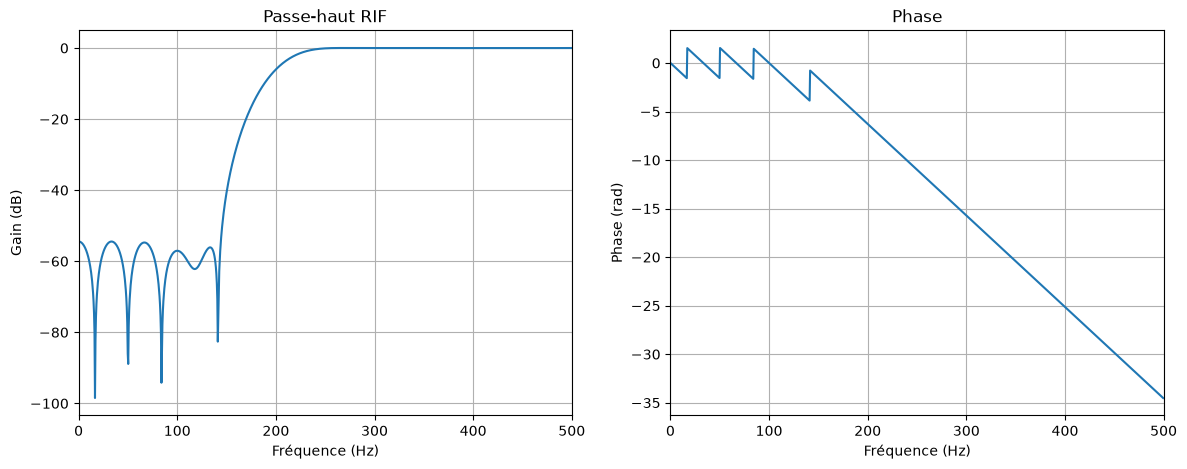

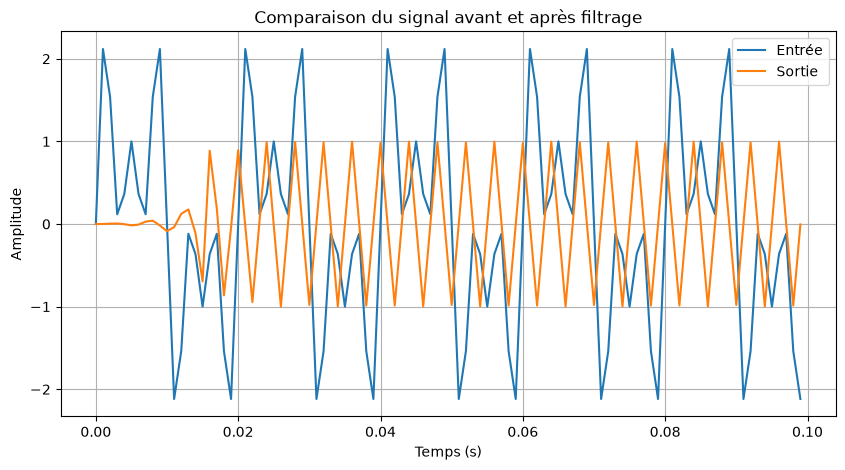

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

fs = 1000
fc = 200
N = 31  # Nombre impair de coefficients

# Conception passe-haut
b = signal.firwin(N, fc, fs=fs, window='hamming', pass_zero='highpass')

# Tracé de la réponse
w, H = signal.freqz(b, a=1, worN=1024)
freqs = w * fs / (2 * np.pi)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(freqs, 20 * np.log10(np.maximum(np.abs(H), 1e-10)))
plt.title('Passe-haut RIF')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Gain (dB)')
plt.xlim(0, 500)
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freqs, np.unwrap(np.angle(H)))
plt.title('Phase')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.xlim(0, 500)
plt.grid()

plt.show()

# Test sur un signal
t = np.linspace(0, 0.1, int(0.1 * fs), endpoint=False)

x = (np.sin(2 * np.pi * 50 * t)
     + np.sin(2 * np.pi * 150 * t)
     + np.sin(2 * np.pi * 250 * t))

y = signal.lfilter(b, 1, x)

plt.figure(figsize=(10, 5))
plt.plot(t, x, label='Entrée')
plt.plot(t, y, label='Sortie')
plt.xlabel('Temps (s)')
plt.ylabel('Amplitude')
plt.title('Comparaison du signal avant et après filtrage')
plt.legend()
plt.grid()
plt.show()

## Exercice 2 – Filtre RII passe-bande (Chebyshev type I)

1. Concevoir un filtre passe-bande RII de type Chebyshev-I avec les spécifications :
   - Bande passante : 100-200 Hz
   - Ondulation dans la bande passante : 1 dB
   - Fréquence d'échantillonnage : 1000 Hz
   - Ordre minimal.
2. Tracer la réponse en gain, la phase, et le diagramme pôles-zéros.
3. Appliquer le filtre à un signal contenant 50 Hz, 150 Hz et 300 Hz. Commenter.

**Code** :

In [ ]:
fs = 1000
Wp = [100, 200]  # bande passante (Hz)
Wp_norm = [Wp[0]/(fs/2), Wp[1]/(fs/2)]
rp = 1  # ondulation en dB

# Conception
order, wn = signal.cheb1ord(Wp_norm, [Wp_norm[0]*0.8, Wp_norm[1]*1.2], rp, 40)
b, a = signal.cheby1(order, rp, wn, btype='bandpass')
print(f"Ordre : {order}")

w, H = signal.freqz(b, a, worN=1024)
freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, 20*np.log10(np.abs(H)))
plt.axvline(100, color='gray', linestyle='--')
plt.axvline(200, color='gray', linestyle='--')
plt.title('Chebyshev-I passe-bande')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 400)
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freqs, np.unwrap(np.angle(H)))
plt.title('Phase')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 400)
plt.grid()
plt.show()

# Test
t = np.linspace(0, 0.1, int(0.1*fs), endpoint=False)
x = np.sin(2*np.pi*50*t) + np.sin(2*np.pi*150*t) + np.sin(2*np.pi*300*t)
y = signal.lfilter(b, a, x)

plt.plot(t, x, label='Entrée')
plt.plot(t, y, label='Sortie')
plt.legend()
plt.grid()
plt.show()

Correction exercice 2

Gabarit retenu (l'énoncé ne donne que la bande passante) :

| Zone | Fréquences | Contrainte |
|---|---|---|
| Bande passante | 100 – 200 Hz | ondulation ≤ 1 dB |
| Bandes coupées | < 70 Hz et > 230 Hz | atténuation ≥ 40 dB |

`cheb1ord` donne l'ordre minimal, puis `cheby1` conçoit le filtre. Pour un passe-bande, l'ordre final est **le double** de l'ordre du prototype passe-bas.

Ordre prototype : 7 | ordre du passe-bande : 14


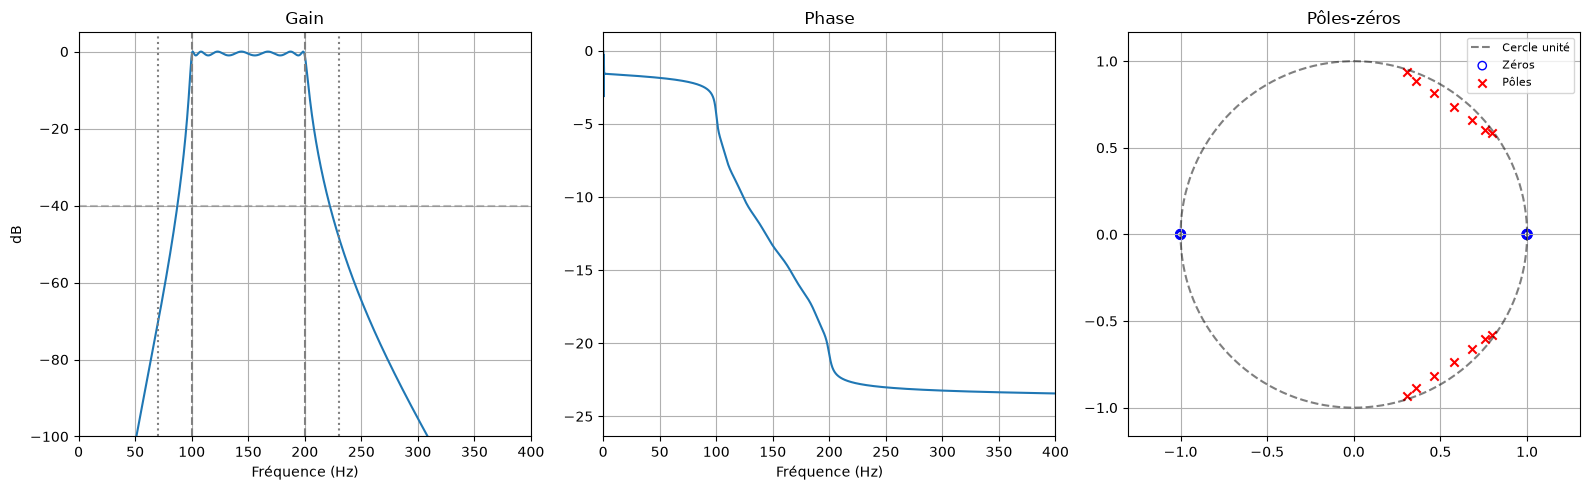

Stable : True


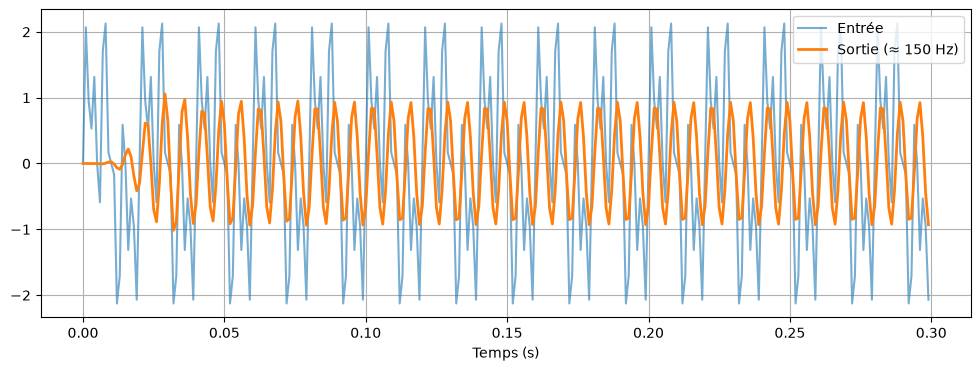

Gain à  50 Hz :  -101.7 dB
Gain à 150 Hz :    -0.6 dB
Gain à 300 Hz :   -95.3 dB


In [9]:
fs = 1000
wp = [100, 200]   # bande passante (Hz)
ws = [70, 230]    # bandes d'arrêt (hypothèse)
rp = 1            # ondulation (dB)
rs = 40           # atténuation (dB)

ordre_proto, wn = signal.cheb1ord(wp, ws, rp, rs, fs=fs)
b, a = signal.cheby1(ordre_proto, rp, wn, btype='bandpass', fs=fs)
print(f"Ordre prototype : {ordre_proto} | ordre du passe-bande : {len(a)-1}")

w, H = signal.freqz(b, a, worN=4096, fs=fs)
zeros, poles, gain = signal.tf2zpk(b, a)

plt.figure(figsize=(16, 5))
plt.subplot(1, 3, 1)
plt.plot(w, 20*np.log10(np.abs(H) + 1e-12))
for f in wp: plt.axvline(f, color='gray', linestyle='--')
for f in ws: plt.axvline(f, color='gray', linestyle=':')
plt.axhline(-rs, color='gray', linestyle='--', alpha=0.5)
plt.title('Gain'); plt.xlabel('Fréquence (Hz)'); plt.ylabel('dB')
plt.xlim(0, 400); plt.ylim(-100, 5); plt.grid()

plt.subplot(1, 3, 2)
plt.plot(w, np.unwrap(np.angle(H)))
plt.title('Phase'); plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 400); plt.grid()

plt.subplot(1, 3, 3)
theta = np.linspace(0, 2*np.pi, 300)
plt.plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.5, label='Cercle unité')
plt.scatter(zeros.real, zeros.imag, marker='o', facecolors='none', edgecolors='b', label='Zéros')
plt.scatter(poles.real, poles.imag, marker='x', color='r', label='Pôles')
plt.axis('equal'); plt.title('Pôles-zéros'); plt.legend(fontsize=8); plt.grid()
plt.tight_layout(); plt.show()
print("Stable :", np.all(np.abs(poles) < 1))

# Application : 50 + 150 + 300 Hz
t = np.arange(0, 0.3, 1/fs)
x = np.sin(2*np.pi*50*t) + np.sin(2*np.pi*150*t) + np.sin(2*np.pi*300*t)
y = signal.lfilter(b, a, x)

plt.figure(figsize=(12, 4))
plt.plot(t, x, label='Entrée', alpha=0.6)
plt.plot(t, y, label='Sortie (≈ 150 Hz)', linewidth=2)
plt.xlabel('Temps (s)'); plt.legend(); plt.grid()
plt.show()

for f in (50, 150, 300):
    _, Hf = signal.freqz(b, a, worN=[f], fs=fs)
    print(f"Gain à {f:3d} Hz : {20*np.log10(abs(Hf[0])):7.1f} dB")

## Exercice 3 – Comparaison de filtres pour un même gabarit

Soit un gabarit de filtre passe-bas :
- Fréquence de coupure : 100 Hz
- Atténuation minimale de 40 dB dans la bande stop à partir de 150 Hz.
- Ondulation en bande passante : 0.5 dB (pour les RII).

1. Concevoir un RIF (Hamming) répondant à ce gabarit (trouver l'ordre nécessaire).
2. Concevoir un RII (Butterworth) répondant à ce gabarit (trouver l'ordre).
3. Comparer les ordres, les réponses en gain et la phase.
4. Quel filtre choisiriez-vous pour une application audio ? Pour une application temps réel ?

**Code** :

In [ ]:
fs = 1000
fc = 100
f_stop = 150
att_stop = 40  # dB

# RIF : ordre estimé par la formule de Kaiser
delta = 10**(-att_stop/20)
A = -20*np.log10(delta)
if A > 21:
    D = (A - 7.95) / 14.36
else:
    D = 0.922
N_est = int(np.ceil(D * 2 * fs / (f_stop - fc)))
print(f"Ordre RIF estimé : {N_est}")

b_fir = signal.firwin(N_est, fc, fs=fs, window=('kaiser', A))

# RII : Butterworth
order_iir = signal.buttord(fc/(fs/2), f_stop/(fs/2), 0.5, att_stop)
b_iir, a_iir = signal.butter(order_iir, fc/(fs/2), btype='low')
print(f"Ordre RII Butterworth : {order_iir}")

# Tracé
w, H_fir = signal.freqz(b_fir, a=1, worN=1024)
_, H_iir = signal.freqz(b_iir, a_iir, worN=1024)
freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 8))
plt.subplot(2, 1, 1)
plt.plot(freqs, 20*np.log10(np.abs(H_fir)), label=f'RIF (ordre {N_est})')
plt.plot(freqs, 20*np.log10(np.abs(H_iir)), label=f'RII (ordre {order_iir})')
plt.axvline(fc, color='gray', linestyle='--')
plt.axvline(f_stop, color='gray', linestyle='--')
plt.axhline(-att_stop, color='gray', linestyle='--')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Gain (dB)')
plt.xlim(0, 250)
plt.ylim(-60, 5)
plt.legend()
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(freqs, np.unwrap(np.angle(H_fir)), label='RIF (phase linéaire)')
plt.plot(freqs, np.unwrap(np.angle(H_iir)), label='RII (phase non linéaire)')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.xlim(0, 250)
plt.legend()
plt.grid()
plt.show()

# Application audio : phase linéaire importante -> RIF.
# Temps réel : RII plus efficace (ordre plus faible).

Correction exercice 3

Gabarit : bande passante jusqu'à 100 Hz, bande d'arrêt à partir de 150 Hz avec ≥ 40 dB, donc $\Delta f = 50$ Hz.

**1. RIF (Hamming)** : $\Delta f \approx 3{,}3\,f_s/N$, d'où
$$ N \approx \frac{3{,}3 \times 1000}{50} = 66 \;\to\; N = 67 \text{ (impair)} $$
Coupure placée au milieu de la transition : $(100+150)/2 = 125$ Hz. Hamming donne ≈ 53 dB d'atténuation, ce qui suffit.

**2. RII (Butterworth)** : `buttord` donne l'ordre minimal (ondulation ≤ 0,5 dB à 100 Hz, ≥ 40 dB à 150 Hz). Attention : il renvoie le couple *(ordre, wn)*.

RIF : N = 67 coefficients (ordre 66)
RII : ordre 13
RIF : min bande passante = -0.01 dB | max bande d'arrêt = -51.7 dB
RII : min bande passante = -0.50 dB | max bande d'arrêt = -41.7 dB
RIF : retard constant = 33 échantillons
RII : retard de groupe à 10/50/100 Hz = [11.8 13.  24. ]


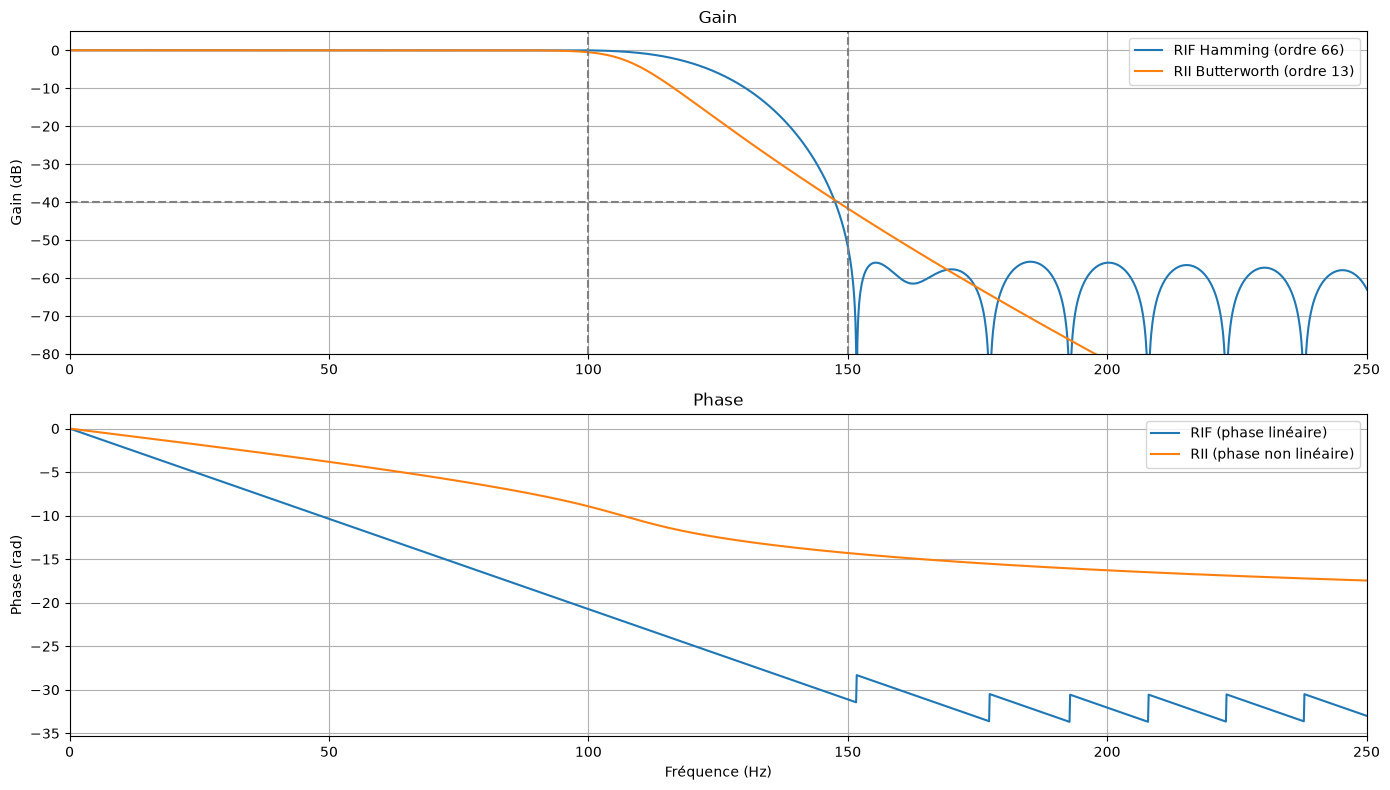

In [10]:
fs = 1000
f_pass, f_stop = 100, 150
att_stop = 40
rp = 0.5

# 1. RIF Hamming
delta_f = f_stop - f_pass
N_fir = int(np.ceil(3.3 * fs / delta_f))
if N_fir % 2 == 0:
    N_fir += 1
fc_fir = (f_pass + f_stop) / 2
b_fir = signal.firwin(N_fir, fc_fir, fs=fs, window='hamming')
print(f"RIF : N = {N_fir} coefficients (ordre {N_fir-1})")

# 2. RII Butterworth
ordre_iir, wn = signal.buttord(f_pass, f_stop, rp, att_stop, fs=fs)
b_iir, a_iir = signal.butter(ordre_iir, wn, btype='low', fs=fs)
print(f"RII : ordre {ordre_iir}")

# 3. Comparaison
w, H_fir = signal.freqz(b_fir, 1, worN=4096, fs=fs)
_, H_iir = signal.freqz(b_iir, a_iir, worN=4096, fs=fs)
dB = lambda H: 20*np.log10(np.abs(H) + 1e-12)

for nom, H in (("RIF", H_fir), ("RII", H_iir)):
    print(f"{nom} : min bande passante = {dB(H[w <= f_pass]).min():.2f} dB | "
          f"max bande d'arrêt = {dB(H[w >= f_stop]).max():.1f} dB")

print(f"RIF : retard constant = {(N_fir-1)/2:.0f} échantillons")
_, gd = signal.group_delay((b_iir, a_iir), w=[10, 50, 100], fs=fs)
print("RII : retard de groupe à 10/50/100 Hz =", np.round(gd, 1))

plt.figure(figsize=(14, 8))
plt.subplot(2, 1, 1)
plt.plot(w, dB(H_fir), label=f'RIF Hamming (ordre {N_fir-1})')
plt.plot(w, dB(H_iir), label=f'RII Butterworth (ordre {ordre_iir})')
plt.axvline(f_pass, color='gray', linestyle='--'); plt.axvline(f_stop, color='gray', linestyle='--')
plt.axhline(-att_stop, color='gray', linestyle='--')
plt.ylabel('Gain (dB)'); plt.xlim(0, 250); plt.ylim(-80, 5)
plt.legend(); plt.grid(); plt.title('Gain')

plt.subplot(2, 1, 2)
plt.plot(w, np.unwrap(np.angle(H_fir)), label='RIF (phase linéaire)')
plt.plot(w, np.unwrap(np.angle(H_iir)), label='RII (phase non linéaire)')
plt.xlabel('Fréquence (Hz)'); plt.ylabel('Phase (rad)')
plt.xlim(0, 250); plt.legend(); plt.grid(); plt.title('Phase')
plt.tight_layout(); plt.show()

## Exercice 4 – Filtre coupe-bande (notch) pour éliminer 50 Hz

1. Concevoir un filtre coupe-bande (notch) de type RII (Butterworth ou Chebyshev) pour supprimer 50 Hz.
   - Largeur de bande : 5 Hz.
   - Fréquence d'échantillonnage : 1000 Hz.
2. Appliquer ce filtre à un signal contenant une sinusoïde à 50 Hz et d'autres fréquences.
3. Observer l'effet sur le signal et son spectre.

**Code** :

In [ ]:
fs = 1000
f0 = 50
Q = f0 / 5  # facteur de qualité

# Notch avec iirnotch (filtre à réjection)
b, a = signal.iirnotch(f0, Q, fs)

w, H = signal.freqz(b, a, worN=1024)
freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, 20*np.log10(np.abs(H)))
plt.axvline(f0, color='gray', linestyle='--')
plt.title('Filtre coupe-bande (notch) à 50 Hz')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 100)
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freqs, np.unwrap(np.angle(H)))
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 100)
plt.grid()
plt.show()

# Test
t = np.linspace(0, 0.2, int(0.2*fs), endpoint=False)
x = np.sin(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*120*t)
y = signal.lfilter(b, a, x)

plt.plot(t, x, label='Entrée (50 Hz + 120 Hz)')
plt.plot(t, y, label='Sortie (50 Hz atténué)')
plt.legend()
plt.grid()
plt.show()

# Spectre
X = np.fft.fft(x)
Y = np.fft.fft(y)
freqs_fft = np.fft.fftfreq(len(x), 1/fs)[:len(x)//2]

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs_fft, np.abs(X[:len(x)//2]) / len(x))
plt.title('Spectre entrée')
plt.xlim(0, 150)
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freqs_fft, np.abs(Y[:len(x)//2]) / len(x))
plt.title('Spectre sortie (50 Hz supprimé)')
plt.xlim(0, 150)
plt.grid()
plt.show()

Correction exercice 4

Facteur de qualité : $Q = \dfrac{f_0}{\Delta f} = \dfrac{50}{5} = 10$.

Deux réalisations RII :
1. `signal.iirnotch(f0, Q, fs)` : ordre 2.
2. `signal.butter(2, [47.5, 52.5], btype='bandstop')` : ordre 4.

Test sur $x(t)=\sin(2\pi\,50t)+0{,}5\sin(2\pi\,120t)$, où le 50 Hz simule le bruit du secteur.

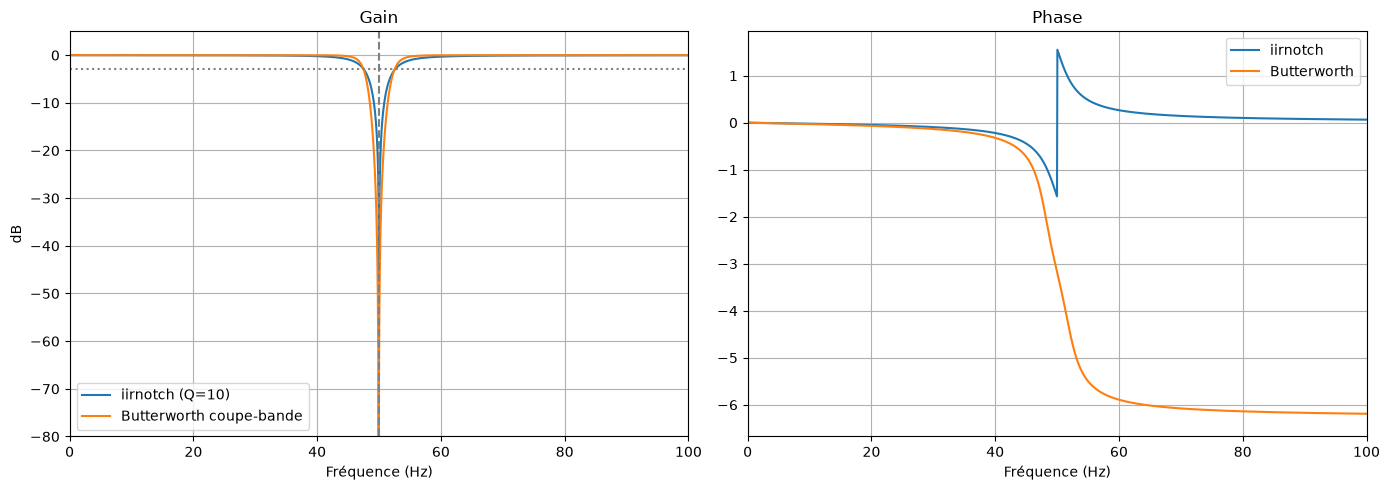

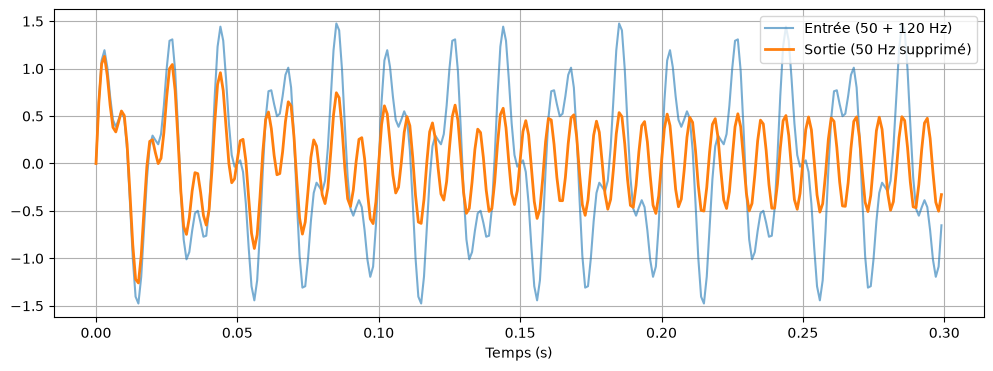

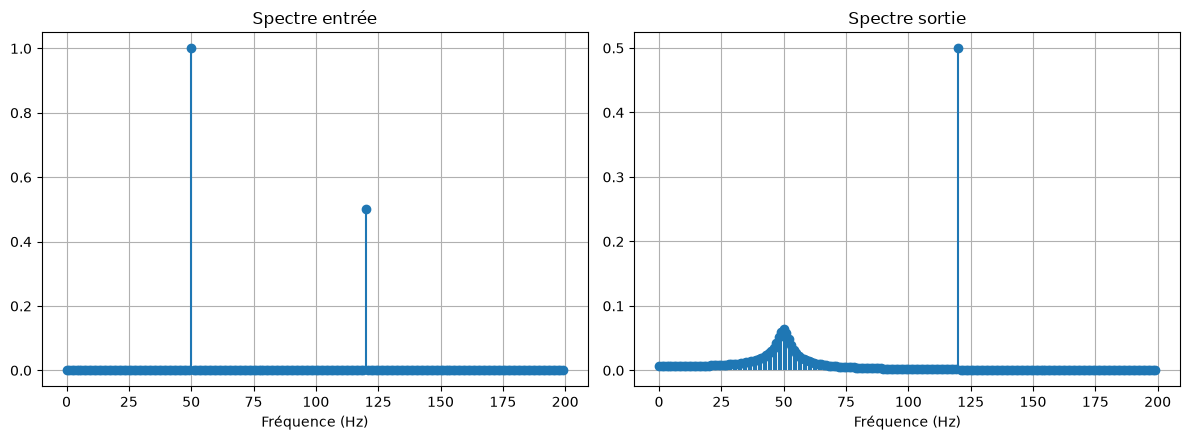

50 Hz  : 1.000 -> 0.0637
120 Hz : 0.500 -> 0.499


In [11]:
fs = 1000
f0 = 50
largeur = 5
Q = f0 / largeur

b_n, a_n = signal.iirnotch(f0, Q, fs=fs)
b_b, a_b = signal.butter(2, [f0 - largeur/2, f0 + largeur/2], btype='bandstop', fs=fs)

w, H_n = signal.freqz(b_n, a_n, worN=8192, fs=fs)
_, H_b = signal.freqz(b_b, a_b, worN=8192, fs=fs)
dB = lambda H: 20*np.log10(np.abs(H) + 1e-12)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(w, dB(H_n), label='iirnotch (Q=10)')
plt.plot(w, dB(H_b), label='Butterworth coupe-bande')
plt.axvline(f0, color='gray', linestyle='--'); plt.axhline(-3, color='gray', linestyle=':')
plt.title('Gain'); plt.xlabel('Fréquence (Hz)'); plt.ylabel('dB')
plt.xlim(0, 100); plt.ylim(-80, 5); plt.legend(); plt.grid()

plt.subplot(1, 2, 2)
plt.plot(w, np.unwrap(np.angle(H_n)), label='iirnotch')
plt.plot(w, np.unwrap(np.angle(H_b)), label='Butterworth')
plt.title('Phase'); plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 100); plt.legend(); plt.grid()
plt.tight_layout(); plt.show()

# Application
t = np.arange(0, 1, 1/fs)
x = np.sin(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*120*t)
y = signal.lfilter(b_n, a_n, x)

plt.figure(figsize=(12, 4))
plt.plot(t[:300], x[:300], label='Entrée (50 + 120 Hz)', alpha=0.6)
plt.plot(t[:300], y[:300], label='Sortie (50 Hz supprimé)', linewidth=2)
plt.xlabel('Temps (s)'); plt.legend(); plt.grid()
plt.show()

# Spectres
f_fft = np.fft.rfftfreq(len(x), 1/fs)
X = np.abs(np.fft.rfft(x)) / len(x) * 2
Y = np.abs(np.fft.rfft(y)) / len(x) * 2

plt.figure(figsize=(12, 4.5))
plt.subplot(1, 2, 1)
plt.stem(f_fft[:200], X[:200], basefmt=' '); plt.title('Spectre entrée'); plt.xlabel('Fréquence (Hz)'); plt.grid()
plt.subplot(1, 2, 2)
plt.stem(f_fft[:200], Y[:200], basefmt=' '); plt.title('Spectre sortie'); plt.xlabel('Fréquence (Hz)'); plt.grid()
plt.tight_layout(); plt.show()

print(f"50 Hz  : {X[50]:.3f} -> {Y[50]:.4f}")
print(f"120 Hz : {X[120]:.3f} -> {Y[120]:.3f}")

## Exercice 5 – Analyse de la réponse impulsionnelle et de la stabilité

Pour un filtre RII donné (par exemple Butterworth ordre 2, fc=0.1), calculer :
1. La réponse impulsionnelle (utiliser `signal.impulse`).
2. La réponse indicielle (entrée échelon).
3. Vérifier la stabilité en traçant les pôles.
4. Modifier l'ordre ou la fréquence de coupure pour observer l'influence sur la stabilité.

**Code** :

In [ ]:
fs = 1000
fc = 100

for order in [2, 4, 6]:
    b, a = signal.butter(order, fc, fs=fs, btype='low')
    
    # Réponse impulsionnelle
    n, h = signal.impulse((b, a, 1/fs), N=50)
    
    # Pôles
    zeros, poles, gain = signal.tf2zpk(b, a)
    
    plt.figure(figsize=(14, 6))
    plt.subplot(1, 3, 1)
    plt.stem(n, h, basefmt=' ')
    plt.title(f'Réponse impulsionnelle (ordre {order})')
    plt.grid()
    
    plt.subplot(1, 3, 2)
    plt.scatter(np.real(poles), np.imag(poles), marker='x', color='r')
    theta = np.linspace(0, 2*np.pi, 200)
    plt.plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.5)
    plt.axis('equal')
    plt.xlim([-2, 2])
    plt.ylim([-2, 2])
    plt.title('Pôles')
    plt.grid()
    
    # Réponse indicielle
    t = np.linspace(0, 0.1, 100)
    t, y_step = signal.step((b, a, 1/fs), T=t)
    plt.subplot(1, 3, 3)
    plt.plot(t, y_step)
    plt.title('Réponse indicielle')
    plt.grid()
    
    plt.tight_layout()
    plt.show()
    
    stable = all(np.abs(p) < 1 for p in poles)
    print(f"Ordre {order} : stable = {stable}")

Correction exercice 5

Le filtre est **numérique** : on utilise `signal.dimpulse` et `signal.dstep`. `signal.impulse` et `signal.step` sont pour les systèmes **analogiques** : un tuple `(b, a, dt)` y serait lu comme *zéros, pôles, gain*, ce qui est faux.

**Critère de stabilité** : un RII causal est stable ⟺ **tous les pôles vérifient $|p| < 1$**. La réponse impulsionnelle tend alors vers 0 et la réponse indicielle converge vers $H(1)$.

Étude : Butterworth passe-bas, $f_c = 100$ Hz, $f_s = 1000$ Hz, ordres 2, 4 et 6.

Ordre 2 : |p|max = 0.6425 -> stable = True
Ordre 4 : |p|max = 0.7954 -> stable = True
Ordre 6 : |p|max = 0.8579 -> stable = True


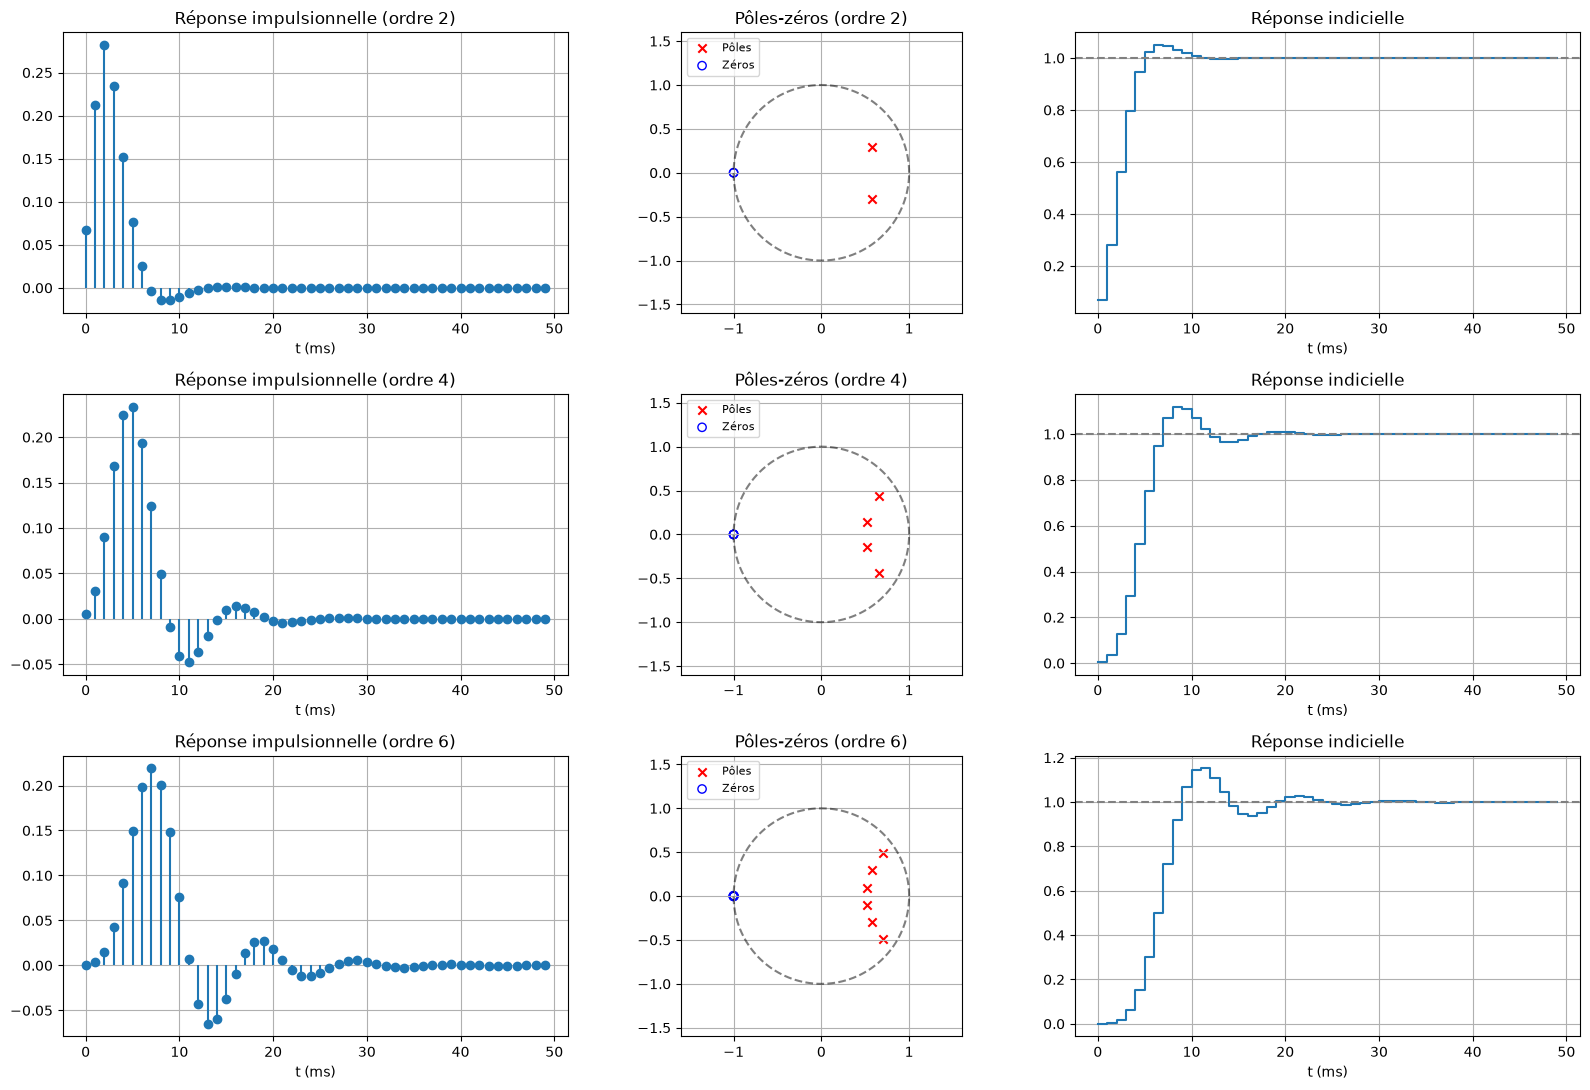

In [12]:
fs = 1000
fc = 100
nb_points = 50
theta = np.linspace(0, 2*np.pi, 300)

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for i, ordre in enumerate([2, 4, 6]):
    b, a = signal.butter(ordre, fc, fs=fs, btype='low')

    t_imp, (h,) = signal.dimpulse((b, a, 1/fs), n=nb_points)
    t_stp, (ystp,) = signal.dstep((b, a, 1/fs), n=nb_points)
    h, ystp = h.ravel(), ystp.ravel()

    zeros, poles, gain = signal.tf2zpk(b, a)

    axes[i, 0].stem(t_imp*1000, h, basefmt=' ')
    axes[i, 0].set_title(f'Réponse impulsionnelle (ordre {ordre})')
    axes[i, 0].set_xlabel('t (ms)'); axes[i, 0].grid()

    axes[i, 1].plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.5)
    axes[i, 1].scatter(poles.real, poles.imag, marker='x', color='r', label='Pôles')
    axes[i, 1].scatter(zeros.real, zeros.imag, marker='o', facecolors='none', edgecolors='b', label='Zéros')
    axes[i, 1].set_title(f'Pôles-zéros (ordre {ordre})')
    axes[i, 1].set_aspect('equal'); axes[i, 1].set_xlim(-1.6, 1.6); axes[i, 1].set_ylim(-1.6, 1.6)
    axes[i, 1].legend(fontsize=8, loc='upper left'); axes[i, 1].grid()

    axes[i, 2].step(t_stp*1000, ystp, where='post')
    axes[i, 2].axhline(1, color='gray', linestyle='--')
    axes[i, 2].set_title('Réponse indicielle'); axes[i, 2].set_xlabel('t (ms)'); axes[i, 2].grid()

    print(f"Ordre {ordre} : |p|max = {np.abs(poles).max():.4f} -> stable = {np.all(np.abs(poles) < 1)}")
plt.tight_layout(); plt.show()

# 5. Livrable Semaine 9

- Remplir les cellules de code avec vos solutions.
- Répondre aux questions théoriques dans les cellules markdown.
- Inclure des commentaires explicatifs.
- Rendre le notebook complet (cellules exécutées).

**Date de rendu** : à définir par l'enseignant.

---